**GENERATİVE ADVERSARİAL NETWORKS(GANs)**


In [ ]:
from keras.layers import Dense,Dropout,Input,ReLU
from keras.models import Model,Sequential,load_model
from keras.datasets import mnist
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.optimizers import Adam
import warnings
warnings.filterwarnings("ignore")



In [ ]:
data = mnist.load_data()

In [ ]:
type(data)

tuple

In [ ]:
(x_train,y_train),(x_test,y_test) = mnist.load_data()

In [ ]:
type(x_train)

numpy.ndarray

In [ ]:
y_train

array([5, 0, 4, ..., 5, 6, 8], dtype=uint8)

In [ ]:
for i in x_train:
  print(i.shape)

In [ ]:
x_train.shape

(60000, 28, 28)

In [ ]:
 x_train = (x_train.astype(np.float32)-127.5)/127.5

In [ ]:
 x_train.shape

(60000, 28, 28)

In [ ]:
x_train

array([[[-1., -1., -1., ..., -1., -1., -1.],
        [-1., -1., -1., ..., -1., -1., -1.],
        [-1., -1., -1., ..., -1., -1., -1.],
        ...,
        [-1., -1., -1., ..., -1., -1., -1.],
        [-1., -1., -1., ..., -1., -1., -1.],
        [-1., -1., -1., ..., -1., -1., -1.]],

       [[-1., -1., -1., ..., -1., -1., -1.],
        [-1., -1., -1., ..., -1., -1., -1.],
        [-1., -1., -1., ..., -1., -1., -1.],
        ...,
        [-1., -1., -1., ..., -1., -1., -1.],
        [-1., -1., -1., ..., -1., -1., -1.],
        [-1., -1., -1., ..., -1., -1., -1.]],

       [[-1., -1., -1., ..., -1., -1., -1.],
        [-1., -1., -1., ..., -1., -1., -1.],
        [-1., -1., -1., ..., -1., -1., -1.],
        ...,
        [-1., -1., -1., ..., -1., -1., -1.],
        [-1., -1., -1., ..., -1., -1., -1.],
        [-1., -1., -1., ..., -1., -1., -1.]],

       ...,

       [[-1., -1., -1., ..., -1., -1., -1.],
        [-1., -1., -1., ..., -1., -1., -1.],
        [-1., -1., -1., ..., -1., -1., -1.

In [ ]:
x_train.shape

(60000, 28, 28)

In [ ]:
x_train = x_train.reshape(x_train.shape[0],x_train.shape[1]*x_train.shape[2])


In [ ]:
x_train

array([[-1., -1., -1., ..., -1., -1., -1.],
       [-1., -1., -1., ..., -1., -1., -1.],
       [-1., -1., -1., ..., -1., -1., -1.],
       ...,
       [-1., -1., -1., ..., -1., -1., -1.],
       [-1., -1., -1., ..., -1., -1., -1.],
       [-1., -1., -1., ..., -1., -1., -1.]], dtype=float32)

In [ ]:
x_train.shape

(60000, 784)

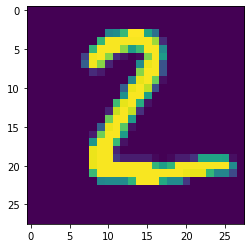

In [ ]:
plt.imshow(x_test[1])

CREATE GENERATOR 

In [ ]:
def create_generator():
  generator = Sequential()
  
  generator.add(Dense(units = 512, input_dim = 100))
  generator.add(ReLU())
  
  generator.add(Dense(units = 512))
  generator.add(ReLU())

  generator.add(Dense(units = 1024))
  generator.add(ReLU())

  generator.add(Dense(units = 784,activation = "tanh"))


  generator.compile(loss = "binary_crossentropy", optimizer = Adam(lr = 0.0001,beta_1 = 0.5))

  return generator


In [ ]:
g = create_generator()
g.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 512)               51712     
                                                                 
 re_lu (ReLU)                (None, 512)               0         
                                                                 
 dense_1 (Dense)             (None, 512)               262656    
                                                                 
 re_lu_1 (ReLU)              (None, 512)               0         
                                                                 
 dense_2 (Dense)             (None, 1024)              525312    
                                                                 
 re_lu_2 (ReLU)              (None, 1024)              0         
                                                                 
 dense_3 (Dense)             (None, 784)               8

In [ ]:
def create_discriminator():
  discriminator = Sequential()
  
  discriminator.add(Dense(units = 1024, input_dim = 784 ))
  discriminator.add(ReLU())
  discriminator.add(Dropout(0.4))

  discriminator.add(Dense(units = 512))
  discriminator.add(ReLU())
  discriminator.add(Dropout(0.4))
  
  discriminator.add(Dense(units = 256))
  discriminator.add(ReLU())

  discriminator.add(Dense(units = 1,activation="sigmoid"))

  discriminator.compile(loss = "binary_crossentropy", optimizer = Adam(lr = 0.0001,beta_1 = 0.5) )

  return discriminator



In [ ]:
d =  create_discriminator()
d.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_4 (Dense)             (None, 1024)              803840    
                                                                 
 re_lu_3 (ReLU)              (None, 1024)              0         
                                                                 
 dropout (Dropout)           (None, 1024)              0         
                                                                 
 dense_5 (Dense)             (None, 512)               524800    
                                                                 
 re_lu_4 (ReLU)              (None, 512)               0         
                                                                 
 dropout_1 (Dropout)         (None, 512)               0         
                                                                 
 dense_6 (Dense)             (None, 256)              

In [ ]:
def create_gan(discriminator,generator):
  discriminator.trainable = False
  gan_input = Input(shape = (100, ) )

  x = generator(gan_input)
  gan_output = discriminator(x)

  gan = Model(inputs = gan_input, outputs = gan_output)

  gan.compile(loss = "binary_crossentropy", optimizer = "adam")
  return gan




In [ ]:
gan = create_gan(d,g)
gan.summary()

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 100)]             0         
                                                                 
 sequential (Sequential)     (None, 784)               1643280   
                                                                 
 sequential_1 (Sequential)   (None, 1)                 1460225   
                                                                 
Total params: 3,103,505
Trainable params: 1,643,280
Non-trainable params: 1,460,225
_________________________________________________________________


In [ ]:

#train 

epochs = 50
batch_size = 256


for e in range(epochs):
  for _ in range(batch_size):
    noise = np.random.normal(0,1, [batch_size,100])

    generated_images = g.predict(noise)

    image_batch = x_train[np.random.randint(low= 0, high = x_train.shape[0],size = batch_size)]

    x = np.concatenate([image_batch, generated_images])

    y_dis = np.zeros(batch_size*2)
    y_dis[:batch_size] = 1

    d.trainable = True
    d.train_on_batch(x,y_dis)

    noise = np.random.normal(0,1,[batch_size,100])

    y_gen = np.ones(batch_size)

    d.trainable = False
    gan.train_on_batch(noise,y_gen)
  print("epochs: ",e)

In [ ]:
import keras
import tensorflow as tf
from keras.models import load_model
#g.save("gans_model.h5")

g_load = load_model("/content/drive/MyDrive/GENERATİVE ADVERSARİAL NETWORKS(GANs)/gans_model.h5")

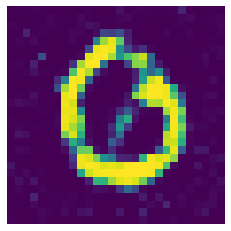

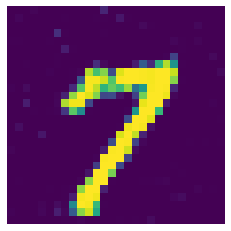

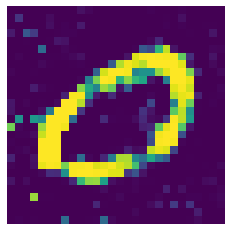

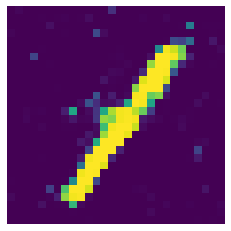

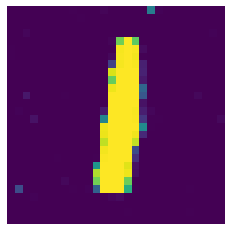

In [ ]:
noise = np.random.normal(loc= 0, scale = 1,size=[100,100])
generated_images =  g_load.predict(noise)
generated_images = generated_images.reshape(100,28,28)

for i in range(0,5,1):
  plt.imshow(generated_images[i], interpolation = "nearest")
  plt.axis("off"),plt.show()



In [ ]:
data =  mnist.load_data()

In [ ]:
data